In [1]:
import sys
from pathlib import Path

src_path = Path.cwd().parent / 'src'

if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from algorithm_creation import AlgorithmConfig, InferenceEngine, GlobalAligner, ImagePreprocessor, SatelliteMatcher
from model_inference import MatchingPipeline

In [2]:
import kornia
config = AlgorithmConfig(
    tile_size=512
)

feature_extractor = kornia.feature.LoFTR(pretrained='outdoor').to(config.device)
engine = InferenceEngine(feature_extractor, config)

 ### Demo 1: shift detection

* **Data source:** Sentinel-2 satellite images taken from the Copernicus Browser of the same location on **July 30, 2026**.
* **Setup:** the second image is shifted slightly downwards from the starting point.
* **Expected result:** because of the vertical shift between the images, the matching lines (inliers) will appear as parallel diagonal or tilted lines connecting the identical points, clearly showing the direction and size of the offset.

/Users/aleksandralitvak/Documents/codes/python/Quantum Test Tasks/Computer vision. Sentinel-2 image matching/venv_cv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


 RESULT
  overlap confidence .............. 0.993  (HIGH — likely the same location)
  inliers ......................... 47005
  total matches ................... 47007
  alignment ....................... OK (aligned)


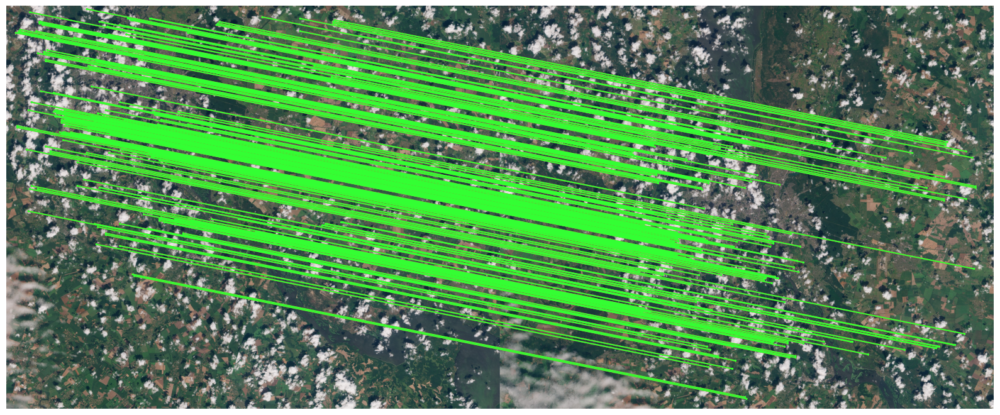

In [3]:
img0 = "../data/demo-1/2026-07-30-00_00_2026-07-30-23_59_Sentinel-2_L1C_True_color-2.jpg"
img1 = "../data/demo-1/2026-07-30-00_00_2026-07-30-23_59_Sentinel-2_L1C_True_color.jpg"

pipeline = MatchingPipeline(engine, config)

result = pipeline(img0, img1)

pipeline.draw_matches(
    matches=result, 
    show_outliers=True,    
    max_points=200,        
    strategy="best"   
)    

### Demo 2: cross-season(winter vs spring)

* **Data source:** Sentinel-2 satellite images from the Copernicus Browser of the same location from different seasons — **January 14, 2026** (winter, snow-covered) and **March 12, 2026** (spring, bare ground).
* **Setup:** no artificial shift is applied. The main challenge is the dramatic change in lighting, colors, and textures caused by weather and seasonal differences.
* **Expected result:** the model successfully finds structural matches and connects identical points between the snowy winter scene and the clear spring scene, proving its ability to handle cross-season satellite imagery.

 RESULT
  overlap confidence .............. 0.991  (HIGH — likely the same location)
  inliers ......................... 36191
  total matches ................... 36268
  alignment ....................... OK (aligned)


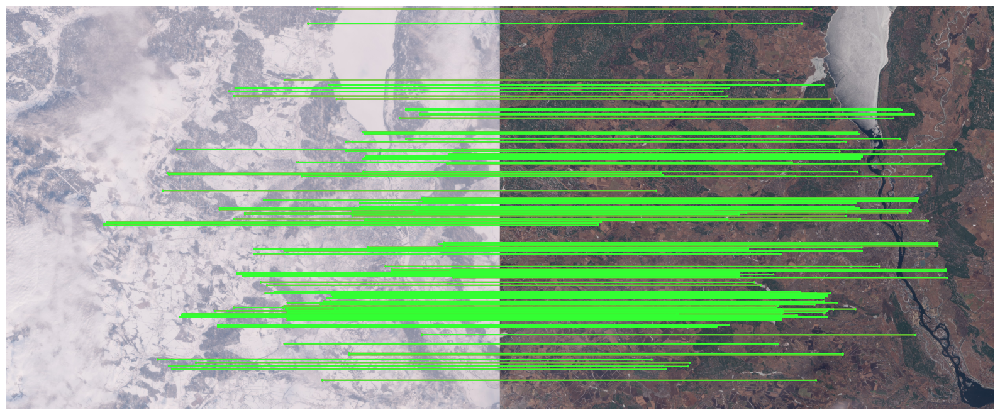

In [4]:
img2 = "../data/demo-2/2026-01-14-00_00_2026-01-14-23_59_Sentinel-2_L1C_True_color.jpg"
img3 = "../data/demo-2/2026-03-12-00_00_2026-03-12-23_59_Sentinel-2_L1C_True_color.jpg"

pipeline = MatchingPipeline(engine, config)

result = pipeline(img2, img3)

pipeline.draw_matches(
    matches=result, 
    show_outliers=True,    
    max_points=200,        
    strategy="best"   
)    

### Demo 3: one season - different location 

* **Data source:** Sentinel-2 images from the Copernicus Browser of two **different locations**, both from **January 14, 2026** (winter, snow-covered).
* **Setup:** no artificial transformation. Both scenes have similar snow textures, which makes this a difficult negative pair.
* **Expected result:** the algorithm should correctly classify this as a NEGATIVE PAIR. Despite having similar winter textures (snow), the geographical locations are completely different. Geometric verification (RANSAC) should filter out any random matches, resulting in a very low number of inliers (below the threshold) and successfully preventing a False Positive.

 ALIGNMENT NOTICE — 2026-01-14-00_00_2026-01-14-23_59_Sentinel-2_L1C_True_color.jpg vs 2026-01-14-00_00_2026-01-14-23_59_Sentinel-2_L1C_True_color-3.jpg
  Standard geometric correction was skipped; evaluating direct co-registration.
------------------------------------------------------------
  anchors selected ................ 8
  anchors matched ................. 1
  candidate tiles scored .......... 35
  candidates passing sanity ....... 1
  best inlier count ............... 4   (required: 15)
  pooled points ................... 4
  pooled inliers .................. 4
  reason .......................... no correction needed (already co-registered) or locations differ
 RESULT
  overlap confidence .............. 0.001  (LOW — likely NOT the same location)
  inliers ......................... 5
  total matches ................... 42
  alignment ....................... NOTE (distinct locations or insufficient overlap)


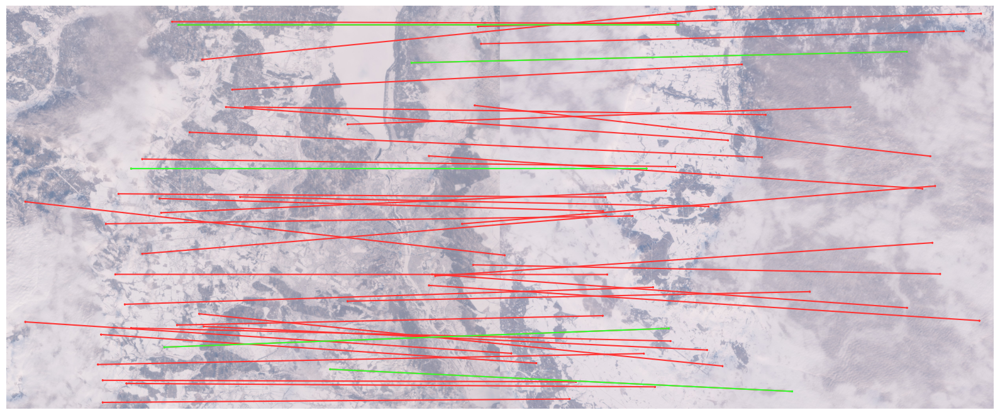

In [5]:
img4 = "../data/demo-3/2026-01-14-00_00_2026-01-14-23_59_Sentinel-2_L1C_True_color.jpg"
img5 = "../data/demo-3/2026-01-14-00_00_2026-01-14-23_59_Sentinel-2_L1C_True_color-3.jpg"

pipeline = MatchingPipeline(engine, config, output=True)

result = pipeline(img4, img5)

pipeline.draw_matches(
    matches=result, 
    show_outliers=True,    
    max_points=200,        
    strategy="best"   
)    

### Demo 4: same location - shifted and rotated
* **Data source:** Sentinel-2 images from the Copernicus Browser of the **same location** on **March 12, 2026** (the river makes the shift easy to follow).
* **Setup:** the second image was transformed artificially: a rightward shift, a **30° counterclockwise rotation**, and auto-crop.
* **Expected result**: 

 RESULT
  overlap confidence .............. 0.986  (HIGH — likely the same location)
  inliers ......................... 26372
  total matches ................... 26375
  alignment ....................... OK (aligned)


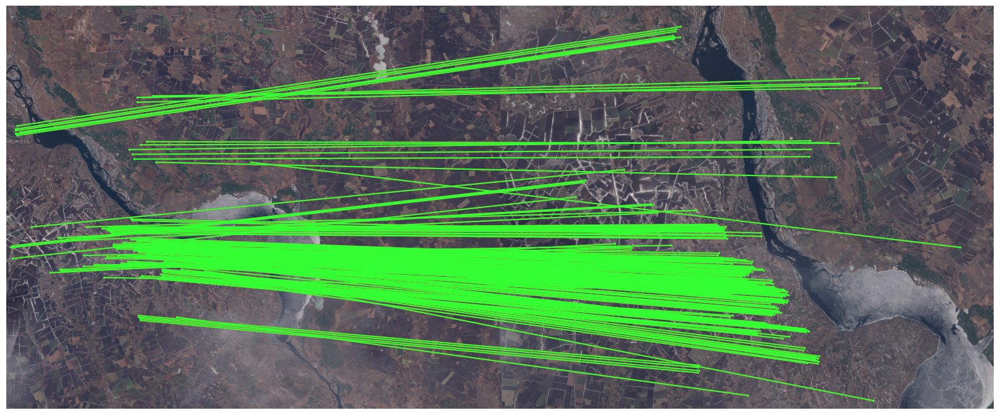

In [ ]:
img6 = "../data/demo-4/2026-03-12-00_00_2026-03-12-23_59_Sentinel-2_L1C_True_color-2.jpg"
img7 = "../data/demo-4/2026-03-12-00_00_2026-03-12-23_59_Sentinel-2_L1C_True_color.jpg"

pipeline = MatchingPipeline(engine, config, output=True)

result = pipeline(img6, img7)

pipeline.draw_matches(
    matches=result, 
    show_outliers=True,    
    max_points=200,        
    # strategy="best"   
)

### Demo 5, part 1: seasonal change with 15° rotation
* **Data source:** Sentinel-2 images of the same location: **July 30, 2026** (summer) and **January 21, 2026** (winter, snow).
* **Setup:** the second image transformed artificially: a rightward shift, a **15° counterclockwise rotation**, and auto-crop — on top of the seasonal appearance change.
* **Expected result**: the seasonal change should reduce the number of raw matches, but stable structures are expected to survive the confidence filter. The spiral search should find the shifted tiles and the homography should absorb the 15° angle, so we expect a HIGH confidence verdict — though lower than in Demo 4.

 RESULT
  overlap confidence .............. 0.922  (HIGH — likely the same location)
  inliers ......................... 6688
  total matches ................... 6722
  alignment ....................... OK (aligned)


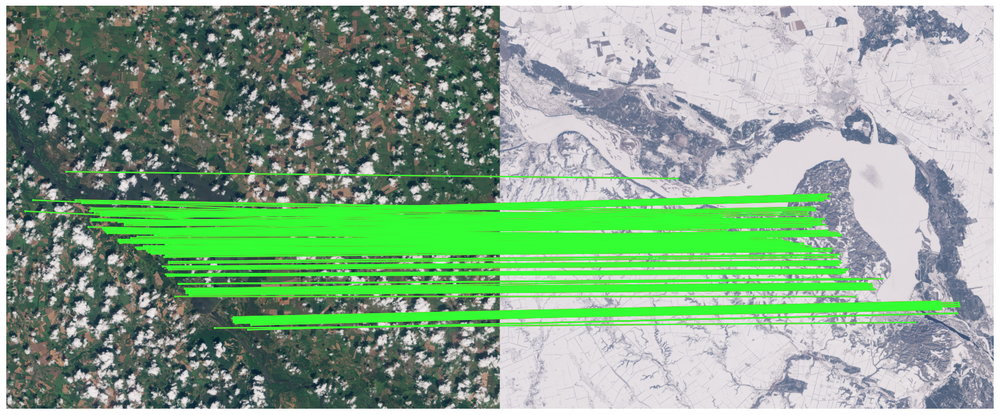

In [7]:
img8 = "../data/demo-5/2026-07-30-00_00_2026-07-30-23_59_Sentinel-2_L1C_True_color.jpg"
img9 = "../data/demo-5/2026-01-21-00_00_2026-01-21-23_59_Sentinel-2_L1C_True_color-15.jpg"

pipeline = MatchingPipeline(engine, config, output=True)

result = pipeline(img8, img9)

pipeline.draw_matches(
    matches=result, 
    show_outliers=True,    
    max_points=200,        
    strategy="best"   
)

### Demo 5, part 2: seasonal change with 45° rotation — expected failure (known limitation)
* **Data source:** the same summer/winter pair as in part 1.
* **Setup:** second image was shifted right, rotated **45° clockwise**, and auto-cropped. Only the rotation angle differs from part 1.
* **Expected result**: the spiral search should scan all candidate tiles, but LoFTR is expected to find too few confident matches because the local content is rotated by 45°. No anchor should reach the 15-inlier threshold, so alignment should fall back to identity and only a handful of inliers should survive the final filter. We expect a LOW confidence verdict — a false negative. 

 ALIGNMENT NOTICE — 2026-07-30-00_00_2026-07-30-23_59_Sentinel-2_L1C_True_color.jpg vs 2026-01-21-00_00_2026-01-21-23_59_Sentinel-2_L1C_True_color-45.jpg
  Standard geometric correction was skipped; evaluating direct co-registration.
------------------------------------------------------------
  anchors selected ................ 8
  anchors matched ................. 0
  candidate tiles scored .......... 16
  candidates passing sanity ....... 0
  best inlier count ............... 0   (required: 15)
  pooled points ................... 0
  pooled inliers .................. 0
  reason .......................... no_anchor_matched
 RESULT
  overlap confidence .............. 0.001  (LOW — likely NOT the same location)
  inliers ......................... 5
  total matches ................... 17
  alignment ....................... NOTE (distinct locations or insufficient overlap)


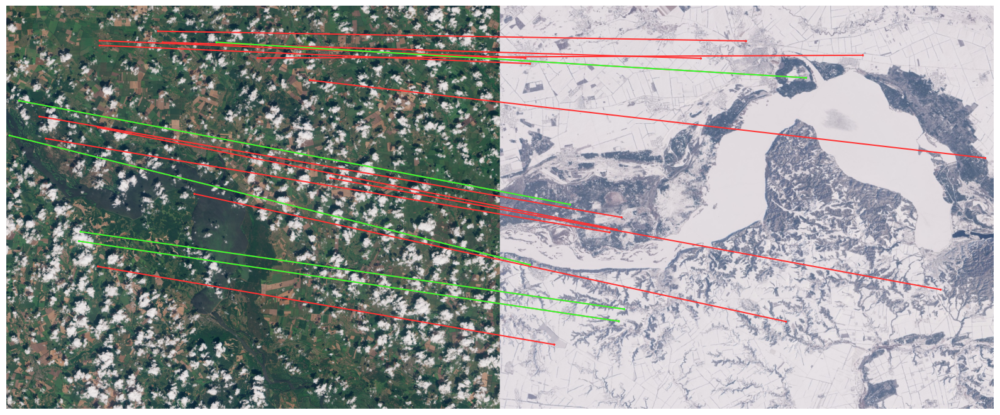

In [9]:
img9 = "../data/demo-5/2026-01-21-00_00_2026-01-21-23_59_Sentinel-2_L1C_True_color-45.jpg"

pipeline = MatchingPipeline(engine, config, output=True)

result = pipeline(img8, img9)

pipeline.draw_matches(
    matches=result, 
    show_outliers=True,    
    max_points=200,        
    strategy="best"   
)

## Conclusion

**Robustness and precision.** across the tested pairs, the pipeline handles seasonal change (Demo 2, Demo 5 part 1) and correctly rejects a different location with similar winter texture (Demo 3). It did not fabricate a match in the tested negative case — no false positive was produced.

**Known limitation.** The current design is not invariant to strong rotation. Moderate angles (15° and 30°) work, but at 45° the matcher fails and the pipeline returns a false negative (Demo 5 part 2). This is a documented limitation of the present algorithm, not a bug.

**Future work.** Replace the core feature matcher with a rotation-invariant LoFTR derivative (for example, SE2-LoFTR) so that tile correspondences survive large in-plane rotations. 

It would also be useful to improve how warped tiles are sized and fitted during alignment—especially when the two images differ in scale—rather than forcing every warped patch into a fixed tile size. For example, if a matched area on the second image covers a much larger or smaller pixel region than a standard tile, squeezing or stretching it into a fixed size can blur details or distort the shape.